In [1]:
import pymongo
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# ---------------------------------------------
# CONFIGURATION
# ---------------------------------------------
MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "validation_db"
COLLECTION_NAME = "document_validations"
OUTPUT_DIR = "./figures_tables/text_analysis_output"

# Create output directory
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------------------------------------
# Connect to MongoDB
# ---------------------------------------------
client = pymongo.MongoClient(MONGO_URI)
collection = client[DB_NAME][COLLECTION_NAME]


In [2]:

# ---------------------------------------------
# Load relevant text validation data
# ---------------------------------------------
print("📥 Fetching data from MongoDB...")

cursor = collection.find({}, {
    "_id": 1,
    "validation_info.checks.text_validation.flags": 1,
    "validation_info.checks.text_validation.metrics": 1
})

records = list(cursor)
print(f"✅ Loaded {len(records)} documents.")

df = pd.json_normalize(records)

# Flatten column names
df.columns = [col.replace("validation_info.checks.text_validation.", "") for col in df.columns]

📥 Fetching data from MongoDB...
✅ Loaded 582683 documents.


In [3]:



# ---------------------------------------------
# Export summary tables
# ---------------------------------------------
print("📊 Generating summary tables...")

# --- 1. Flag Summary ---
flag_cols = [col for col in df.columns if col.startswith("flags.")]
flag_summary = df[flag_cols].sum().sort_values(ascending=False).rename("count").reset_index()
flag_summary.columns = ["flag", "count"]
flag_summary["percent"] = 100 * flag_summary["count"] / len(df)

flag_summary.to_csv(os.path.join(OUTPUT_DIR, "flag_summary.csv"), index=False)
print(flag_summary)

# --- 2. Metric Descriptives ---
metric_cols = [
    "metrics.abstract_chars", "metrics.fulltext_chars",
    "metrics.abstract_ws_ratio", "metrics.fulltext_ws_ratio",
    "metrics.abstract_ascii_ratio", "metrics.fulltext_ascii_ratio",
    "metrics.abstract_sentence_count", "metrics.fulltext_sentence_count",
    "metrics.fulltext_heading_markers", "metrics.language_score",
    "metrics.rouge1_recall", "metrics.abstract_embedding_norm"
]

metric_summary = df[metric_cols].describe().T.round(3)
metric_summary.to_csv(os.path.join(OUTPUT_DIR, "metric_summary.csv"))
print(metric_summary)


📊 Generating summary tables...
                                           flag   count    percent
0   flags.abstract_embedding_missing_or_invalid  122286  20.986711
1             flags.abstract_low_sentence_count   92386  15.855276
2                flags.abstract_low_ascii_ratio   87668  15.045574
3                      flags.abstract_too_short   83877  14.394963
4           flags.abstract_low_whitespace_ratio   82743  14.200346
5                      flags.low_rouge1_overlap   65835  11.298596
6                flags.fulltext_low_ascii_ratio   60399  10.365671
7           flags.fulltext_low_whitespace_ratio   22438   3.850807
8            flags.fulltext_has_corrupted_chars   12252   2.102687
9     flags.language_mismatch_or_low_confidence    4936   0.847116
10            flags.fulltext_low_sentence_count    3913   0.671549
11           flags.abstract_has_corrupted_chars     322   0.055262
12              flags.language_detection_failed       1   0.000172
13                     flags.fu

📈 Creating histogram plot with legends inside red flagged region...


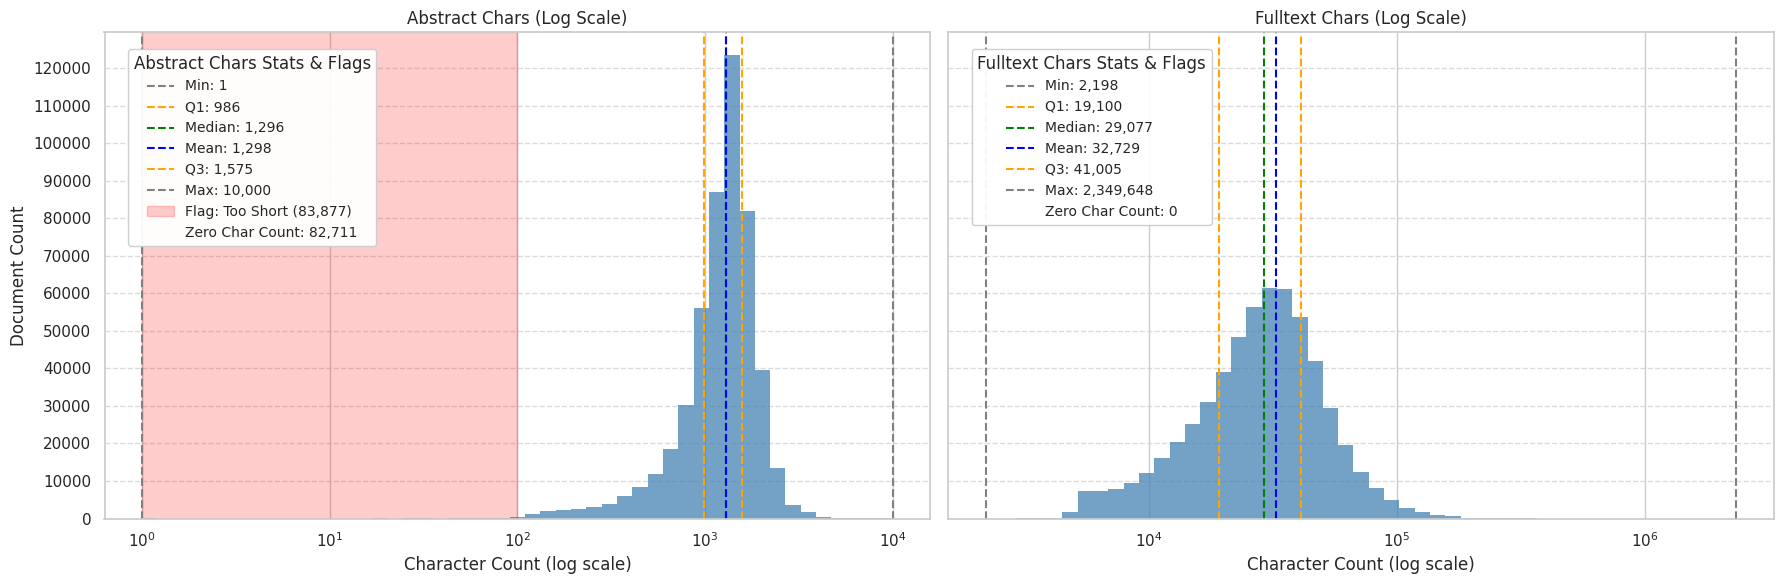

In [4]:
# ---------------------------------------------
# Generate Side-by-Side Histograms with Internal Legends and Flag/Zero Char Counts
# ---------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("📈 Creating histogram plot with legends inside red flagged region...")

sns.set(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for i, col in enumerate(["abstract_chars", "fulltext_chars"]):
    ax = axes[i]

    metric_col = f"metrics.{col}"
    data = df[metric_col].dropna()
    data = data[data > 0]

    if data.empty:
        print(f"⚠️ Skipping {col}: No data after filtering.")
        continue

    # Summary statistics
    stats = {
        "Min": data.min(),
        "Q1": data.quantile(0.25),
        "Median": data.median(),
        "Mean": data.mean(),
        "Q3": data.quantile(0.75),
        "Max": data.max()
    }

    # Log bins
    bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 50)
    sns.histplot(data, bins=bins, kde=False, color="steelblue", ax=ax)
    ax.set_xscale("log")

    # Stat line colors
    colors = {
        "Min": "gray",
        "Q1": "orange",
        "Median": "green",
        "Mean": "blue",
        "Q3": "orange",
        "Max": "gray"
    }

    stat_handles = []
    stat_labels = []

    for stat_name, value in stats.items():
        line = ax.axvline(
            x=value, linestyle="--", color=colors[stat_name], linewidth=1.5,
            label=f"{stat_name}: {int(value):,}"
        )
        stat_handles.append(line)
        stat_labels.append(line.get_label())

    # Highlight "too short" flag region
    flag_col = f"flags.{col.replace('_chars', '')}_too_short"
    flagged_patch = None
    if flag_col in df.columns:
        flagged_docs = df[df[flag_col] == True]
        flagged_max = flagged_docs[metric_col].max()
        flagged_count = flagged_docs.shape[0]

        if not pd.isna(flagged_max):
            flagged_patch = ax.axvspan(
                xmin=1, xmax=flagged_max, color="red", alpha=0.2,
                label=f"Flag: Too Short ({flagged_count:,})"
            )
            stat_handles.append(flagged_patch)
            stat_labels.append(f"Flag: Too Short ({flagged_count:,})")

    # Count zero-character documents and add to legend
    zero_count = df[df[metric_col] == 0].shape[0]
    zero_line = ax.axhline(y=0, color='white', alpha=0, label=f"Zero Char Count: {zero_count:,}")
    stat_handles.append(zero_line)
    stat_labels.append(f"Zero Char Count: {zero_count:,}")

    # Plot settings
    ax.set_title(f"{col.replace('_', ' ').title()} (Log Scale)")
    ax.set_xlabel("Character Count (log scale)")
    if i == 0:
        ax.set_ylabel("Document Count")
    ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=15))
    ax.grid(axis="y", linestyle="--", alpha=0.7)

    # --- Legend inside red region (top-left) ---
    ax.legend(
        handles=stat_handles,
        labels=stat_labels,
        title=f"{col.replace('_', ' ').title()} Stats & Flags",
        loc='upper left',
        bbox_to_anchor=(0.02, 0.98),
        fontsize="small",
        title_fontsize="medium",
        framealpha=0.95,
        facecolor='white'
    )

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "abstract_fulltext_hist_legends_inside_red.png"))
plt.show()
plt.close()


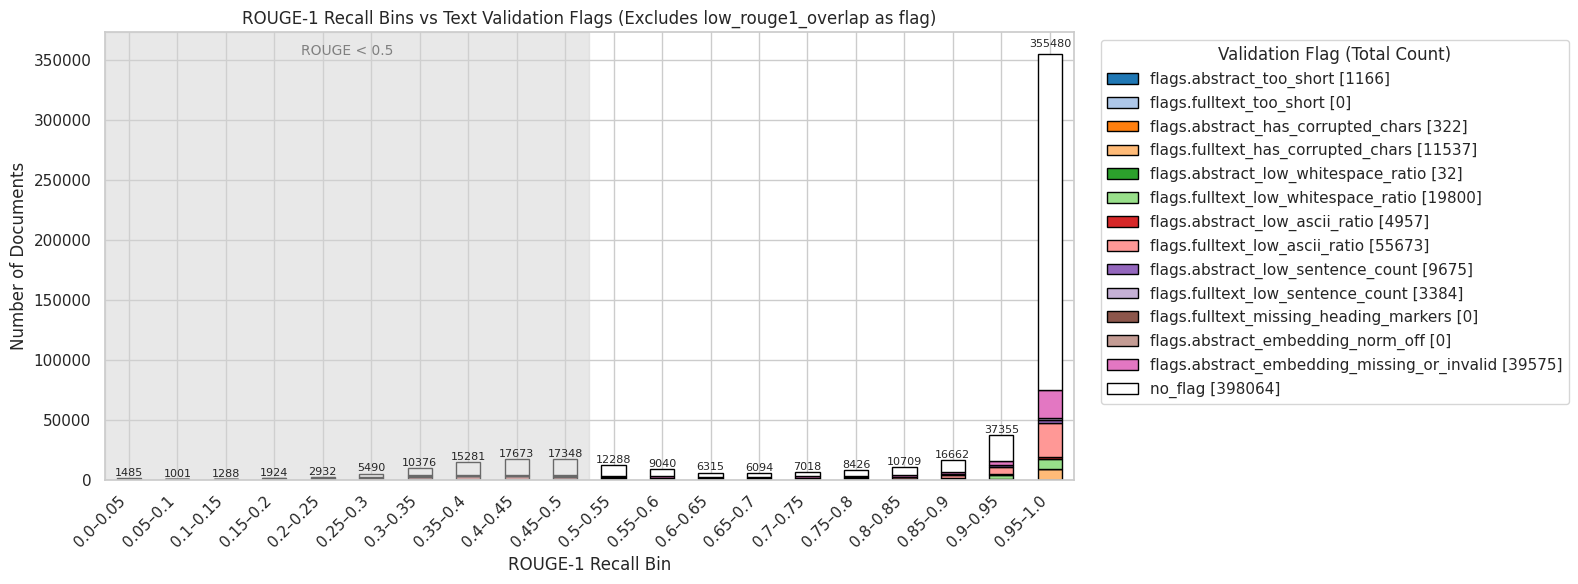

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Ensure output directory exists
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Identify relevant flags (exclude low_rouge1_overlap from list)
flag_cols = [col for col in df.columns if col.startswith("flags.") and (
    ("abstract" in col or "fulltext" in col) or ("rouge1" in col and "low_rouge1_overlap" not in col))]

# 2. Prepare data
cols_to_use = ["metrics.rouge1_recall"] + flag_cols + ["flags.low_rouge1_overlap"]
data = df[cols_to_use].dropna(subset=["metrics.rouge1_recall"])

# 3. Add 'no_flag' column: treat low_rouge1_overlap as non-flag
data["no_flag"] = (~data[flag_cols].fillna(False).any(axis=1))

# 4. Bin ROUGE-1 recall scores
bins = np.linspace(0, 1, 21)
labels = [f"{round(bins[i], 2)}–{round(bins[i + 1], 2)}" for i in range(len(bins) - 1)]
data["rouge_bin"] = pd.cut(data["metrics.rouge1_recall"], bins=bins, labels=labels, include_lowest=True)

# 5. Count flags per ROUGE bin
all_flags = flag_cols + ["no_flag"]
flag_bin_counts = pd.DataFrame(0, index=labels, columns=all_flags)

for flag in flag_cols:
    flagged_docs = data[data[flag] == True]
    bin_counts = flagged_docs["rouge_bin"].value_counts().reindex(labels, fill_value=0)
    flag_bin_counts[flag] = bin_counts

# Count no-flag docs
no_flag_counts = data[data["no_flag"] == True]["rouge_bin"].value_counts().reindex(labels, fill_value=0)
flag_bin_counts["no_flag"] = no_flag_counts

# 6. Rename columns to include total counts
flag_totals = flag_bin_counts.sum()
renamed_cols = {col: f"{col} [{int(flag_totals[col])}]" for col in flag_bin_counts.columns}
flag_bin_counts_renamed = flag_bin_counts.rename(columns=renamed_cols)

# 7. Define colors (white for no_flag, rest from tab20)
num_flags = len(flag_bin_counts.columns) - 1  # excluding no_flag
colors = sns.color_palette("tab20", n_colors=num_flags)
colors.append("#ffffff")  # white for no_flag
column_order = list(flag_bin_counts_renamed.columns)
color_dict = dict(zip(column_order, colors))
color_list = [color_dict[col] for col in column_order]

# 8. Plot
fig, ax = plt.subplots(figsize=(16, 6))
flag_bin_counts_renamed.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=color_list,
    edgecolor="black"
)

# 9. Add total document count on top of each bar
bar_totals = flag_bin_counts.sum(axis=1)
for i, (x, total) in enumerate(zip(ax.get_xticks(), bar_totals)):
    if total > 0:
        ax.text(x, total * 1.01, f"{int(total)}",
                ha='center', va='bottom', fontsize=8, rotation=0)

# 10. Final touches
plt.title("ROUGE-1 Recall Bins vs Text Validation Flags (Excludes low_rouge1_overlap as flag)")
plt.xlabel("ROUGE-1 Recall Bin")
plt.ylabel("Number of Documents")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="Validation Flag (Total Count)",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
# Highlight ROUGE bins < 0.5
ax.axvspan(-0.5, 9.5, color='lightgray', alpha=0.5, label='ROUGE < 0.5')
ax.text(4.5, ax.get_ylim()[1] * 0.95, "ROUGE < 0.5", ha='center', color='gray', fontsize=10)

plt.tight_layout()

# 11. Save figure
plt.savefig(os.path.join(OUTPUT_DIR, "rouge1_recall_flags_exclude_lowrouge1_as_flag.png"))
plt.show()


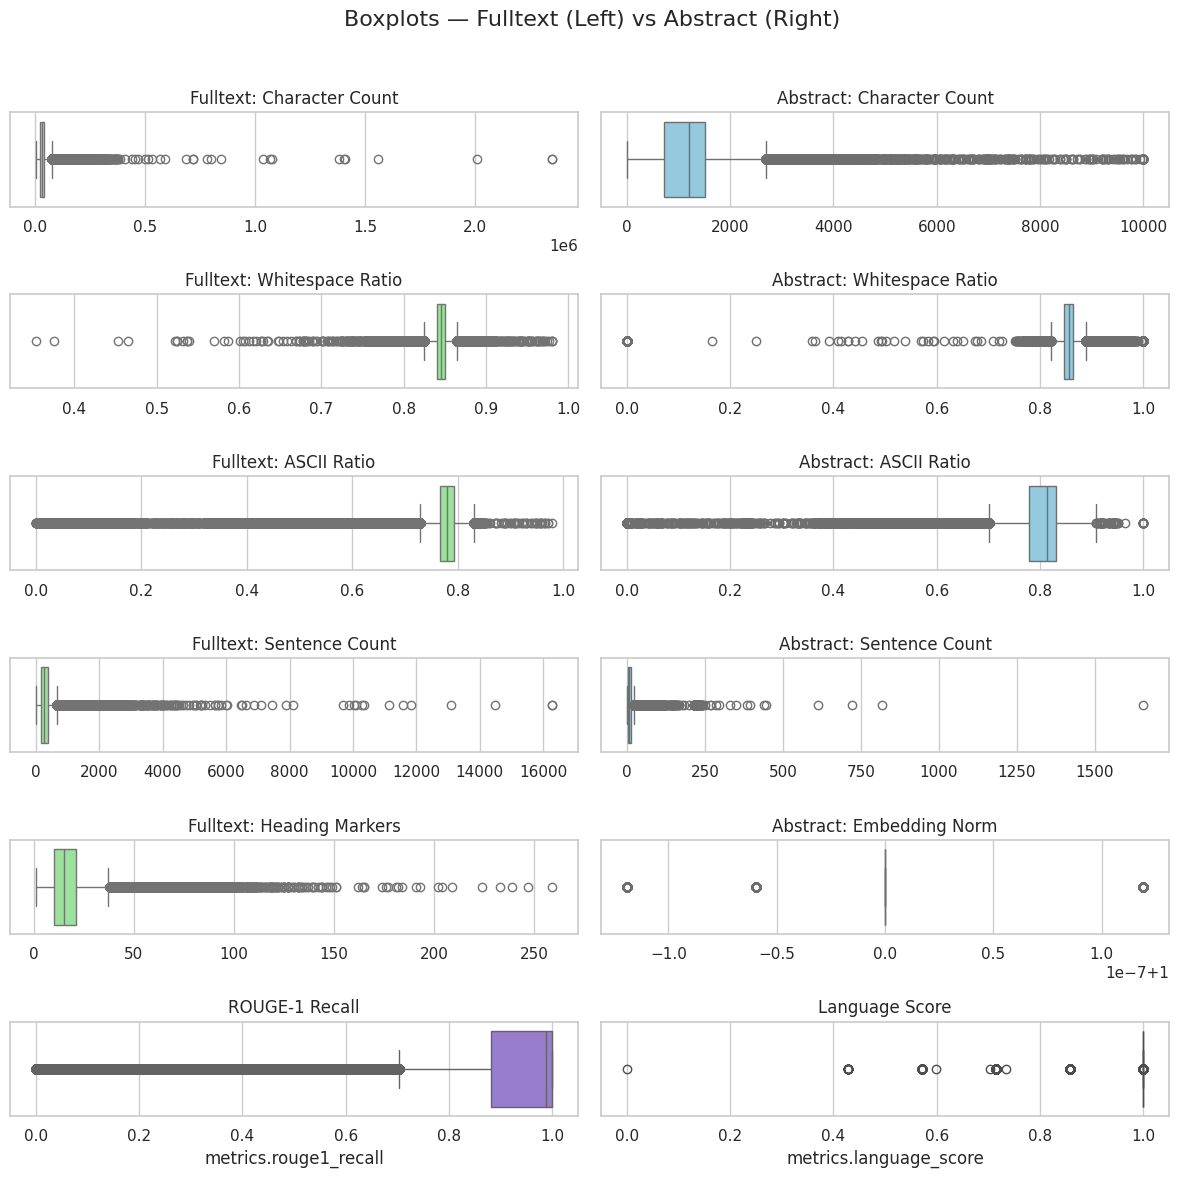

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- Define mappings ---
abstract_metrics_keys = {
    "Character Count": "metrics.abstract_chars",
    "Whitespace Ratio": "metrics.abstract_ws_ratio",
    "ASCII Ratio": "metrics.abstract_ascii_ratio",
    "Sentence Count": "metrics.abstract_sentence_count",
    "Embedding Norm": "metrics.abstract_embedding_norm"
}

fulltext_metrics_keys = {
    "Character Count": "metrics.fulltext_chars",
    "Whitespace Ratio": "metrics.fulltext_ws_ratio",
    "ASCII Ratio": "metrics.fulltext_ascii_ratio",
    "Sentence Count": "metrics.fulltext_sentence_count",
    "Heading Markers": "metrics.fulltext_heading_markers"
}

# --- Separate metric labels for abstract and fulltext ---
abstract_labels = list(abstract_metrics_keys.keys())
fulltext_labels = list(fulltext_metrics_keys.keys())

# --- Prepare DataFrames ---
abstract_df = df[[abstract_metrics_keys[k] for k in abstract_labels]].copy()
abstract_df.columns = abstract_labels

fulltext_df = df[[fulltext_metrics_keys[k] for k in fulltext_labels]].copy()
fulltext_df.columns = fulltext_labels

# --- Special metrics ---
rouge_series = df["metrics.rouge1_recall"]
lang_score_series = df["metrics.language_score"]

# --- Create subplot grid ---
num_rows = max(len(fulltext_labels), len(abstract_labels))
fig, axes = plt.subplots(num_rows + 1, 2, figsize=(12, 2 * (num_rows + 1)), sharex=False)
fig.suptitle("Boxplots — Fulltext (Left) vs Abstract (Right)", fontsize=16)

# --- Plot fulltext metrics ---
for i, label in enumerate(fulltext_labels):
    sns.boxplot(x=fulltext_df[label], ax=axes[i, 0], color="lightgreen")
    axes[i, 0].set_title(f"Fulltext: {label}")
    axes[i, 0].set_xlabel("")

# --- Plot abstract metrics ---
for i, label in enumerate(abstract_labels):
    sns.boxplot(x=abstract_df[label], ax=axes[i, 1], color="skyblue")
    axes[i, 1].set_title(f"Abstract: {label}")
    axes[i, 1].set_xlabel("")

# --- Final row: rouge1_recall vs language_score ---
sns.boxplot(x=rouge_series.dropna(), ax=axes[-1, 0], color="mediumpurple")
axes[-1, 0].set_title("ROUGE-1 Recall")

sns.boxplot(x=lang_score_series.dropna(), ax=axes[-1, 1], color="orange")
axes[-1, 1].set_title("Language Score")

# --- Save & Show ---
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join(OUTPUT_DIR, "side_by_side_metrics_boxplots_combined.png"))
plt.show()
plt.close()


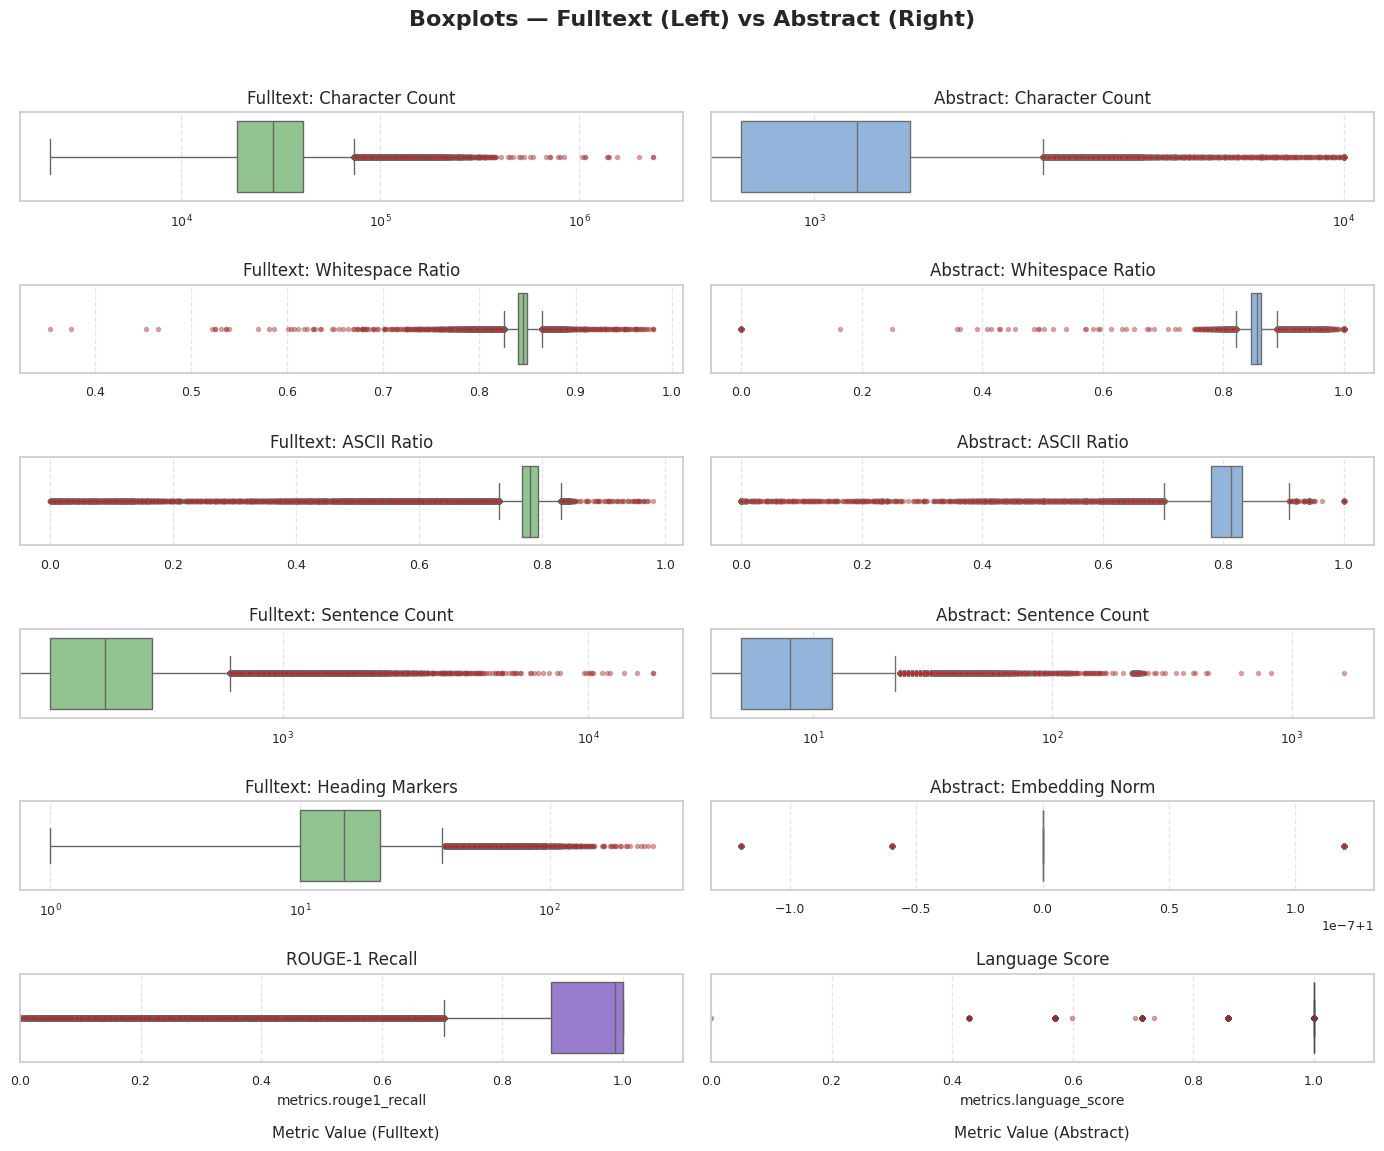

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# --- Define metric mappings ---
abstract_metrics_keys = {
    "Character Count": "metrics.abstract_chars",
    "Whitespace Ratio": "metrics.abstract_ws_ratio",
    "ASCII Ratio": "metrics.abstract_ascii_ratio",
    "Sentence Count": "metrics.abstract_sentence_count",
    "Embedding Norm": "metrics.abstract_embedding_norm"
}

fulltext_metrics_keys = {
    "Character Count": "metrics.fulltext_chars",
    "Whitespace Ratio": "metrics.fulltext_ws_ratio",
    "ASCII Ratio": "metrics.fulltext_ascii_ratio",
    "Sentence Count": "metrics.fulltext_sentence_count",
    "Heading Markers": "metrics.fulltext_heading_markers"
}

# --- Separate metric labels ---
abstract_labels = list(abstract_metrics_keys.keys())
fulltext_labels = list(fulltext_metrics_keys.keys())

# --- Prepare DataFrames ---
abstract_df = df[[abstract_metrics_keys[k] for k in abstract_labels]].copy()
abstract_df.columns = abstract_labels

fulltext_df = df[[fulltext_metrics_keys[k] for k in fulltext_labels]].copy()
fulltext_df.columns = fulltext_labels

# --- Special metrics ---
rouge_series = df["metrics.rouge1_recall"]
lang_score_series = df["metrics.language_score"]

# --- Plot style settings ---
fulltext_color = "#88CC88"
abstract_color = "#88B4E7"
rouge_color = "mediumpurple"
lang_color = "orange"
flierprops = dict(marker='o', markersize=3, markerfacecolor='red', alpha=0.4)

sns.set_style("whitegrid")
plt.rcParams.update({
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9
})

# --- Metrics that should use log scale ---
log_scale_metrics = {"Character Count", "Sentence Count", "Heading Markers"}

# --- Create subplot grid ---
num_rows = max(len(fulltext_labels), len(abstract_labels))
fig, axes = plt.subplots(num_rows + 1, 2, figsize=(14, 2 * (num_rows + 1)), sharex=False)
fig.suptitle("Boxplots — Fulltext (Left) vs Abstract (Right)", fontsize=16, weight="bold")

# --- Plot fulltext metrics ---
for i, label in enumerate(fulltext_labels):
    sns.boxplot(
        x=fulltext_df[label], ax=axes[i, 0], color=fulltext_color,
        flierprops=flierprops
    )
    axes[i, 0].set_title(f"Fulltext: {label}")
    axes[i, 0].set_xlabel("")
    axes[i, 0].grid(axis='x', linestyle='--', alpha=0.5)

    # Apply log scale if metric is in the list
    if label in log_scale_metrics and (fulltext_df[label] > 0).any():
        axes[i, 0].set_xscale("log")

# --- Plot abstract metrics ---
for i, label in enumerate(abstract_labels):
    sns.boxplot(
        x=abstract_df[label], ax=axes[i, 1], color=abstract_color,
        flierprops=flierprops
    )
    axes[i, 1].set_title(f"Abstract: {label}")
    axes[i, 1].set_xlabel("")
    axes[i, 1].grid(axis='x', linestyle='--', alpha=0.5)

    if label in log_scale_metrics and (abstract_df[label] > 0).any():
        axes[i, 1].set_xscale("log")

# --- Final row: ROUGE-1 Recall and Language Score ---
sns.boxplot(x=rouge_series.dropna(), ax=axes[-1, 0], color=rouge_color, flierprops=flierprops)
axes[-1, 0].set_title("ROUGE-1 Recall")
axes[-1, 0].grid(axis='x', linestyle='--', alpha=0.5)
axes[-1, 0].set_xlim(0, 1.1)

sns.boxplot(x=lang_score_series.dropna(), ax=axes[-1, 1], color=lang_color, flierprops=flierprops)
axes[-1, 1].set_title("Language Score")
axes[-1, 1].grid(axis='x', linestyle='--', alpha=0.5)
axes[-1, 1].set_xlim(0, 1.1)

# --- Global axis labels ---
fig.text(0.26, 0.04, "Metric Value (Fulltext)", ha='center', fontsize=11)
fig.text(0.75, 0.04, "Metric Value (Abstract)", ha='center', fontsize=11)

# --- Save & Show ---
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.savefig(os.path.join(OUTPUT_DIR, "side_by_side_metrics_boxplots_updated.png"), dpi=300)
plt.show()
plt.close()


In [8]:

# --- Load Data ---
cursor = collection.find({}, {
    "_id": 1,
    "validation_info.checks.text_validation.metrics": 1,
    "validation_info.checks.text_validation.flags": 1
})
records = list(cursor)
df = pd.json_normalize(records)
df.columns = [col.replace("validation_info.checks.text_validation.", "") for col in df.columns]

# --- Define Rule Masks with Updated Thresholds ---
rules = {
    "abstract_chars_too_short": df["metrics.abstract_chars"] < 200,
    "abstract_chars_too_long": df["metrics.abstract_chars"] > 8000,
    "abstract_ws_ratio_low": df["metrics.abstract_ws_ratio"] < 0.7,
    "abstract_ascii_ratio_low": df["metrics.abstract_ascii_ratio"] < 0.3,
    "abstract_sentence_count_low": df["metrics.abstract_sentence_count"] < 1,
    "abstract_sentence_count_high": df["metrics.abstract_sentence_count"] > 100,
    "fulltext_chars_too_short": df["metrics.fulltext_chars"] < 1000,
    "fulltext_chars_too_long": df["metrics.fulltext_chars"] > 500_000,
    "fulltext_ws_ratio_low": df["metrics.fulltext_ws_ratio"] < 0.7,
    "fulltext_ascii_ratio_low": df["metrics.fulltext_ascii_ratio"] < 0.3,
    "fulltext_sentence_count_low": df["metrics.fulltext_sentence_count"] < 10,
    "fulltext_sentence_count_high": df["metrics.fulltext_sentence_count"] > 10000,
    "language_score_low": df["metrics.language_score"] < 0.5,
    "rouge1_recall_low": df["metrics.rouge1_recall"] < 0.1
}

# --- Apply Each Rule and Save to Separate CSV ---
total_flagged = 0

for rule_name, mask in rules.items():
    rule_df = df[mask].copy()
    if not rule_df.empty:
        file_path = os.path.join(OUTPUT_DIR, f"{rule_name}.csv")
        rule_df.to_csv(file_path, index=False)
        print(f"📁 {len(rule_df)} docs saved to: {file_path}")
        total_flagged += len(rule_df)

print(f"\n✅ Done! Total (non-unique) flagged documents across all rules: {total_flagged}")


📁 90210 docs saved to: ./figures_tables/text_analysis_output/abstract_chars_too_short.csv
📁 121 docs saved to: ./figures_tables/text_analysis_output/abstract_chars_too_long.csv
📁 82740 docs saved to: ./figures_tables/text_analysis_output/abstract_ws_ratio_low.csv
📁 83097 docs saved to: ./figures_tables/text_analysis_output/abstract_ascii_ratio_low.csv
📁 83730 docs saved to: ./figures_tables/text_analysis_output/abstract_sentence_count_low.csv
📁 397 docs saved to: ./figures_tables/text_analysis_output/abstract_sentence_count_high.csv
📁 20 docs saved to: ./figures_tables/text_analysis_output/fulltext_chars_too_long.csv
📁 50 docs saved to: ./figures_tables/text_analysis_output/fulltext_ws_ratio_low.csv
📁 1157 docs saved to: ./figures_tables/text_analysis_output/fulltext_ascii_ratio_low.csv
📁 44 docs saved to: ./figures_tables/text_analysis_output/fulltext_sentence_count_low.csv
📁 11 docs saved to: ./figures_tables/text_analysis_output/fulltext_sentence_count_high.csv
📁 19 docs saved to: .

In [9]:
# Filter: Abstract ASCII ratio < 0.5 and abstract has content
low_ascii_abstract_df = df[
    (df["metrics.abstract_chars"] > 0) &
    (df["metrics.abstract_ascii_ratio"] < 0.5)
].copy()

# Filter: Fulltext ASCII ratio < 0.5 and fulltext has content
low_ascii_fulltext_df = df[
    (df["metrics.fulltext_chars"] > 0) &
    (df["metrics.fulltext_ascii_ratio"] < 0.5)
].copy()

# Define log columns (include only if present)
abstract_log_columns = [
    "_id",
    "metrics.abstract_ascii_ratio",
    "metrics.abstract_ws_ratio",
    "metrics.abstract_chars",
    "metrics.abstract_sentence_count",
    "metrics.language",
    "metrics.language_score",
    "validation_info.checks.text_validation.flags.abstract_low_ascii_ratio"
]
abstract_log_columns = [col for col in abstract_log_columns if col in df.columns]

fulltext_log_columns = [
    "_id",
    "metrics.fulltext_ascii_ratio",
    "metrics.fulltext_ws_ratio",
    "metrics.fulltext_chars",
    "metrics.fulltext_sentence_count",
    "metrics.language",
    "metrics.language_score",
    "validation_info.checks.text_validation.flags.fulltext_low_ascii_ratio"
]
fulltext_log_columns = [col for col in fulltext_log_columns if col in df.columns]

# Save logs to CSV
abstract_log_path = os.path.join(OUTPUT_DIR, "abstract_low_ascii_ratio_docs.csv")
fulltext_log_path = os.path.join(OUTPUT_DIR, "fulltext_low_ascii_ratio_docs.csv")

low_ascii_abstract_df[abstract_log_columns].to_csv(abstract_log_path, index=False)
low_ascii_fulltext_df[fulltext_log_columns].to_csv(fulltext_log_path, index=False)

print(f"📁 Abstract log saved: {abstract_log_path} ({len(low_ascii_abstract_df)} docs)")
print(f"📁 Fulltext log saved: {fulltext_log_path} ({len(low_ascii_fulltext_df)} docs)")


📁 Abstract log saved: ./figures_tables/text_analysis_output/abstract_low_ascii_ratio_docs.csv (762 docs)
📁 Fulltext log saved: ./figures_tables/text_analysis_output/fulltext_low_ascii_ratio_docs.csv (2004 docs)


In [10]:
# Filter for non-English or low-confidence language detection
non_english_df = df[
    (df["metrics.language"] != "en") |
    (df["metrics.language_score"] < 0.5)
].copy()

# Select relevant columns
non_english_log_columns = [
    "_id",
    "metrics.language",
    "metrics.language_score",
    "metrics.abstract_chars",
    "metrics.fulltext_chars",
    "validation_info.checks.text_validation.flags.language_mismatch_or_low_confidence"
]
non_english_log_columns = [col for col in non_english_log_columns if col in df.columns]

# Save to CSV
non_english_log_path = os.path.join(OUTPUT_DIR, "non_english_docs.csv")
non_english_df[non_english_log_columns].to_csv(non_english_log_path, index=False)

print(f"🌐 Logged {len(non_english_df)} non-English or low-confidence documents to:")
print(f"➡️ {non_english_log_path}")


🌐 Logged 4521 non-English or low-confidence documents to:
➡️ ./figures_tables/text_analysis_output/non_english_docs.csv


⚠️ Dropping zero-variance flags: ['flags.fulltext_too_short', 'flags.fulltext_missing_heading_markers', 'flags.abstract_embedding_norm_off']


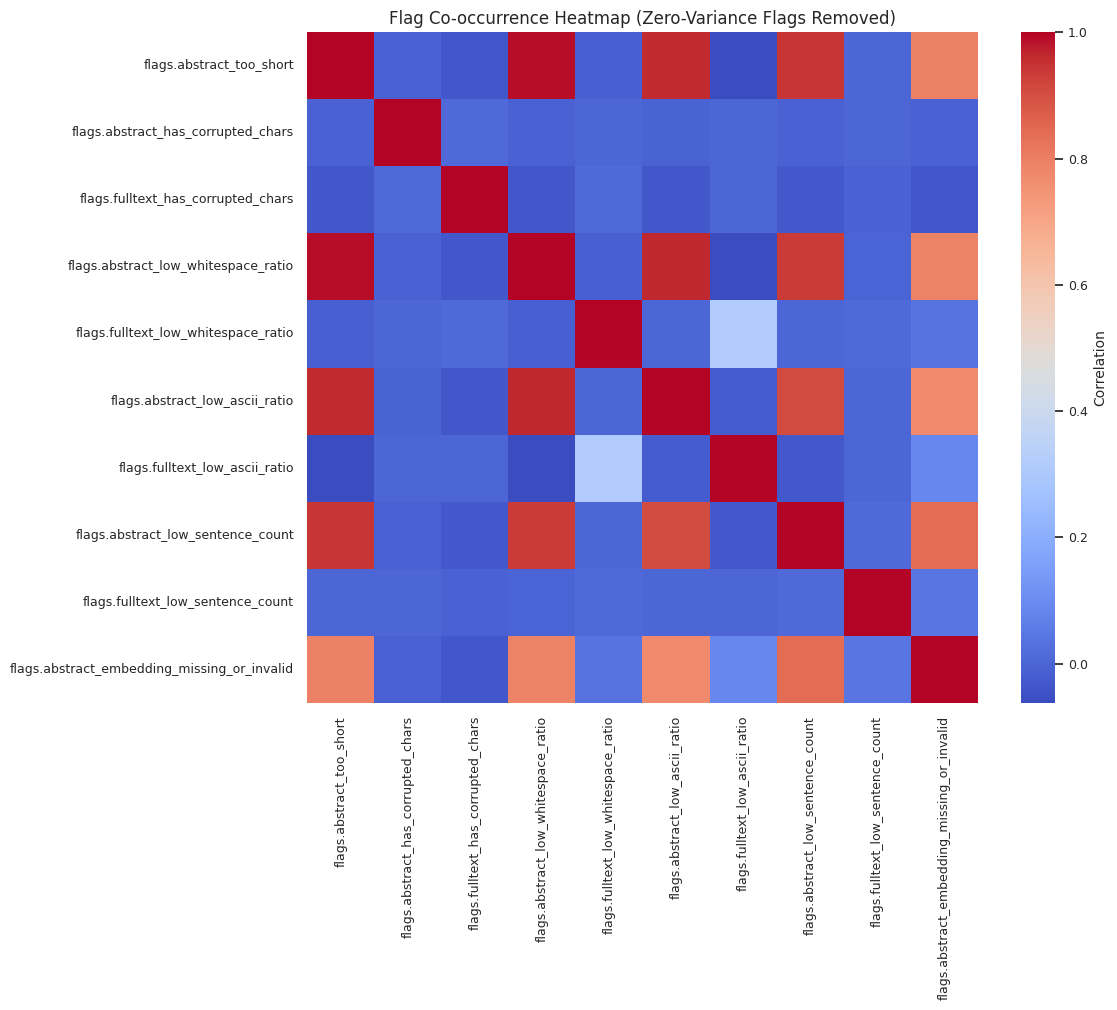

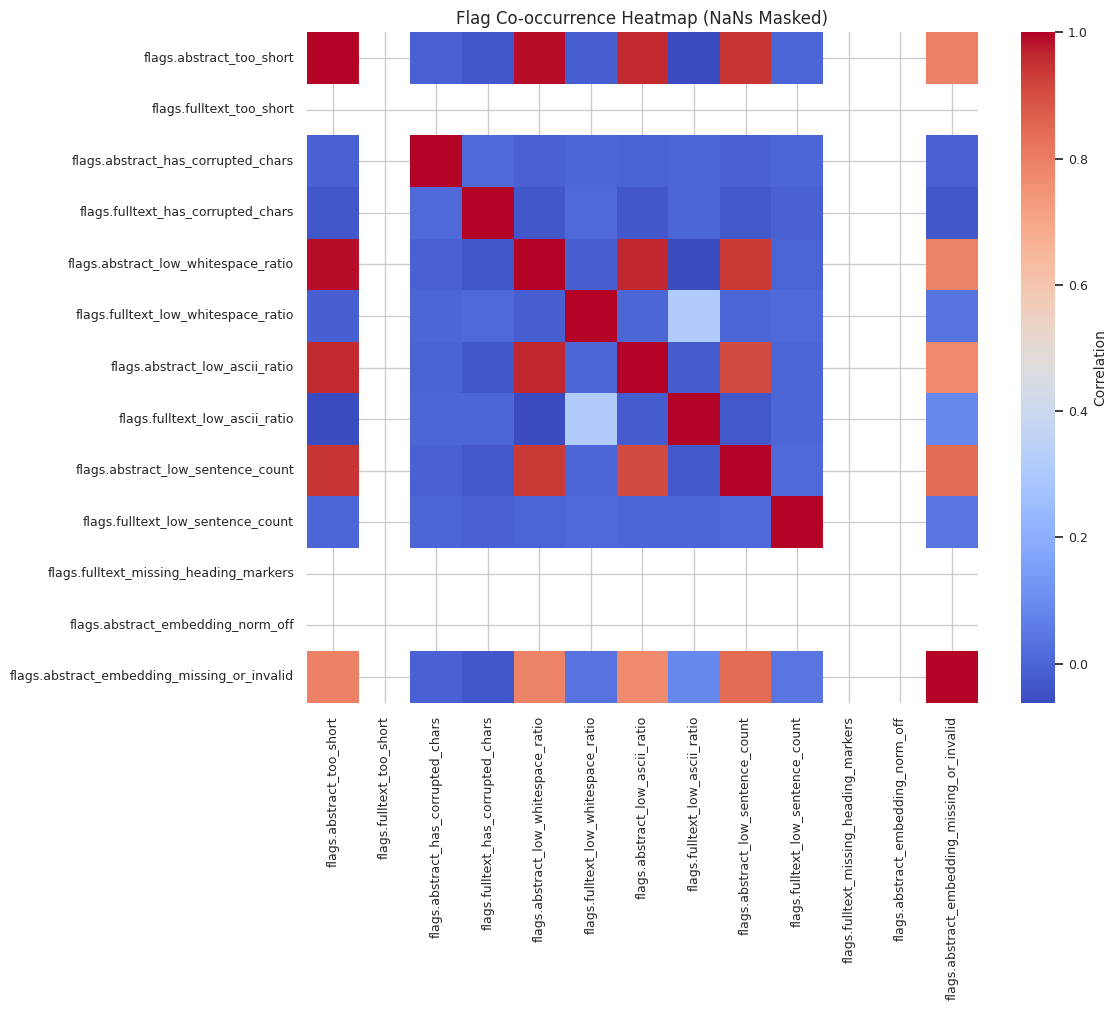

In [11]:
# --- Heatmap: Flag Co-occurrence ---
flag_df = df[flag_cols].astype(bool)

# Identify and drop zero-variance flags
zero_var_flags = flag_df.columns[flag_df.nunique() <= 1]
if len(zero_var_flags) > 0:
    print("⚠️ Dropping zero-variance flags:", zero_var_flags.tolist())
    flag_df = flag_df.drop(columns=zero_var_flags)

# Compute correlation
corr = flag_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", square=True, annot=False, cbar_kws={'label': 'Correlation'})
plt.title("Flag Co-occurrence Heatmap (Zero-Variance Flags Removed)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "flag_heatmap_cleaned.png"))
plt.show()
plt.close()

# --- Heatmap: Flag Co-occurrence with NaN Masking ---
flag_df = df[flag_cols].astype(bool)
corr = flag_df.corr()

# Plot heatmap with NaNs masked (shown as white)
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    square=True,
    annot=False,
    mask=corr.isnull(),
    cbar_kws={'label': 'Correlation'}
)
plt.title("Flag Co-occurrence Heatmap (NaNs Masked)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "flag_heatmap_masked.png"))
plt.show()
plt.close()



⚠️ Dropping zero-variance flags: ['flags.fulltext_too_short', 'flags.fulltext_missing_heading_markers', 'flags.abstract_embedding_norm_off']


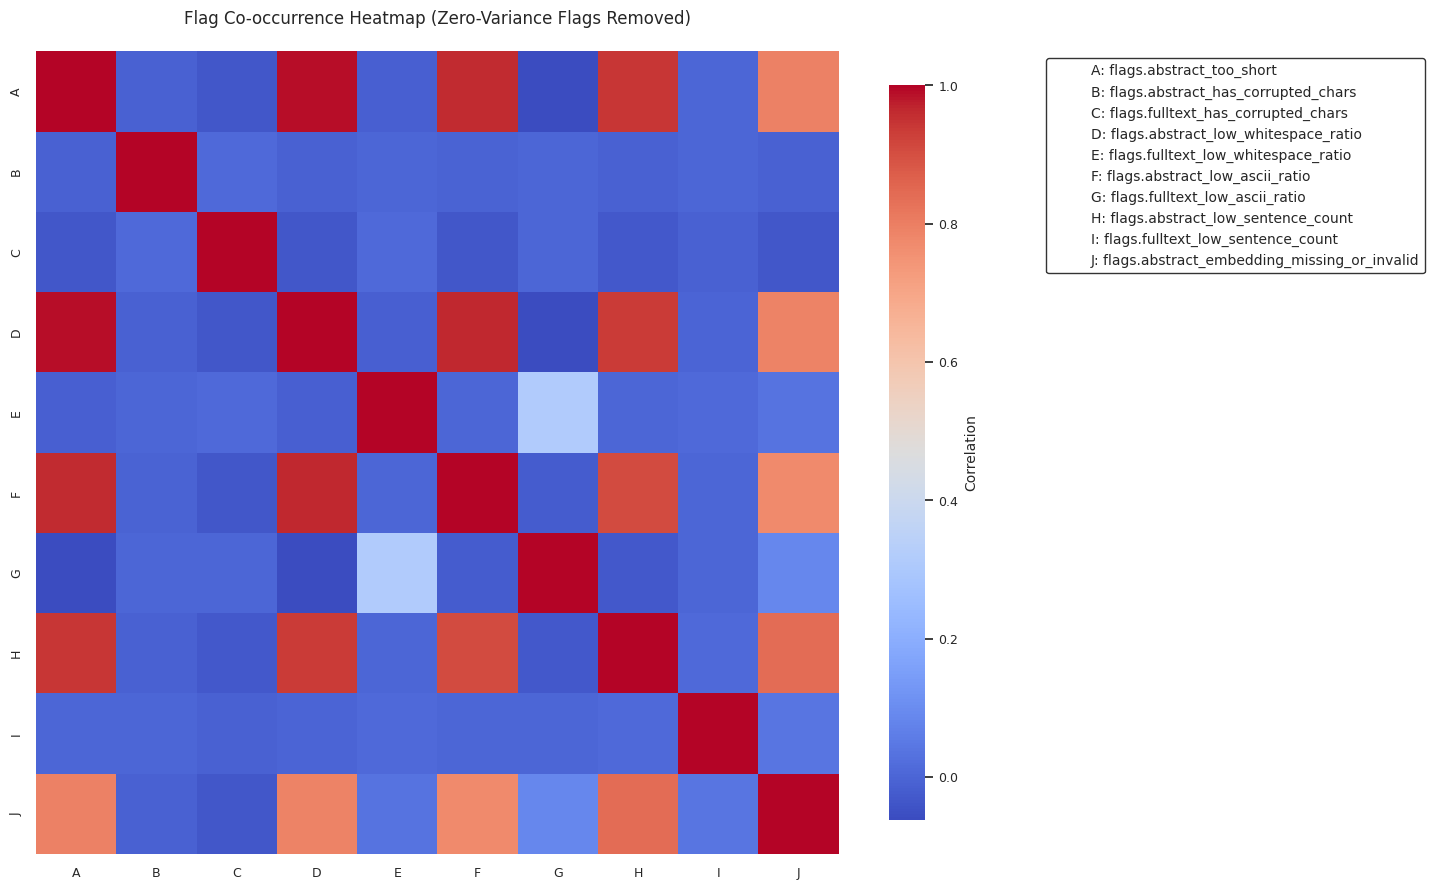

⚠️ Dropping zero-variance flags: ['flags.fulltext_too_short', 'flags.fulltext_missing_heading_markers', 'flags.abstract_embedding_norm_off']


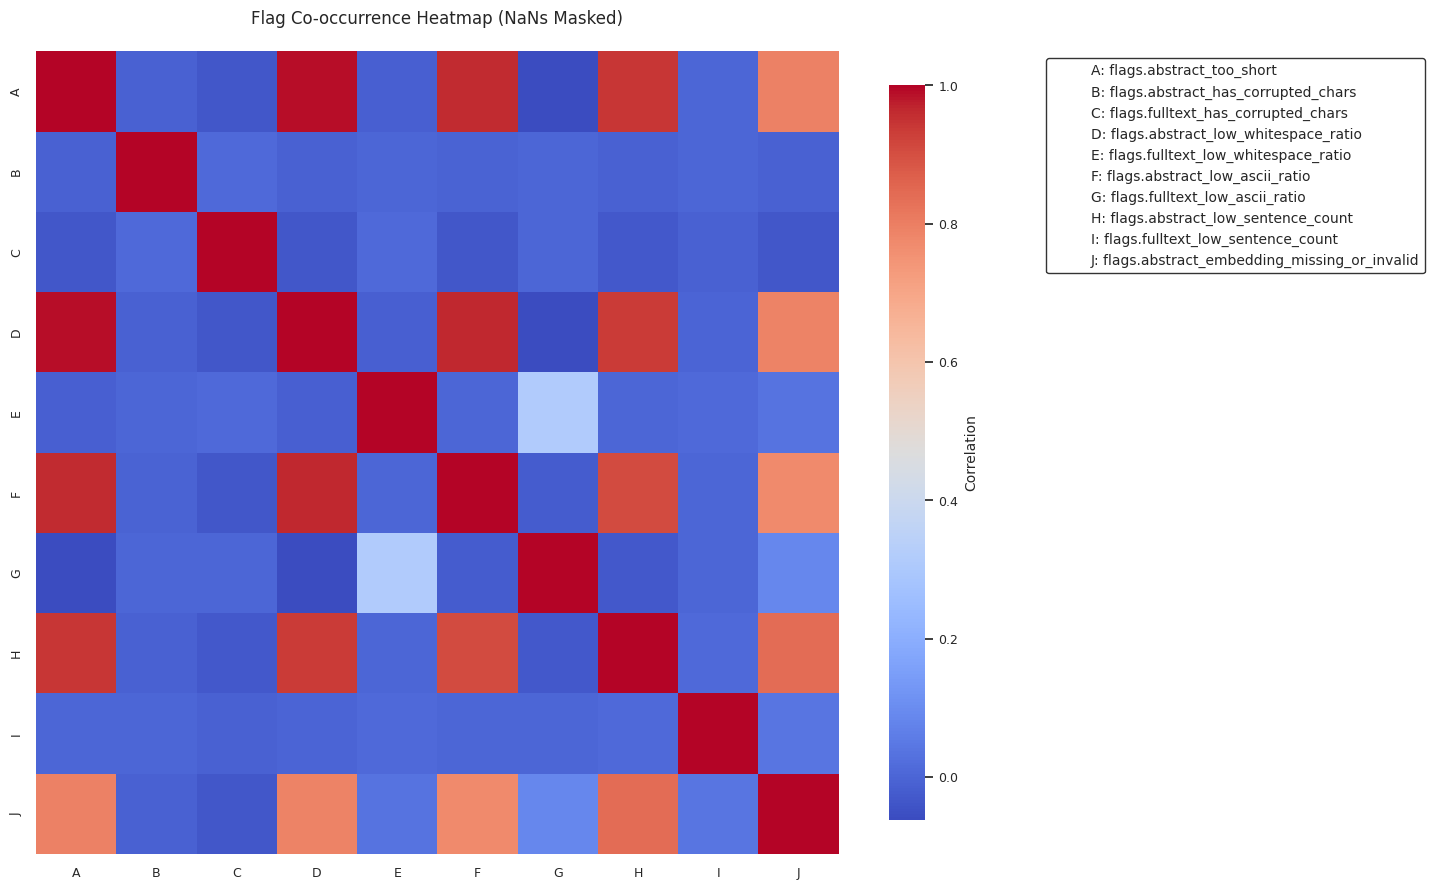

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
import string
import os

def plot_flag_heatmap(flag_df, title, output_path, mask_nans=False):
    """
    Plots a flag co-occurrence heatmap with short codes and legend.

    Parameters
    ----------
    flag_df : pd.DataFrame
        Boolean dataframe of flags.
    title : str
        Title of the heatmap.
    output_path : str
        File path to save the figure.
    mask_nans : bool
        Whether to mask NaN correlations in the heatmap.
    """
    # Drop zero-variance flags
    zero_var_flags = flag_df.columns[flag_df.nunique() <= 1]
    if len(zero_var_flags) > 0:
        print(f"⚠️ Dropping zero-variance flags: {zero_var_flags.tolist()}")
        flag_df = flag_df.drop(columns=zero_var_flags)

    # Compute correlation
    corr = flag_df.corr()

    # Create short codes
    codes = list(string.ascii_uppercase[:len(flag_df.columns)])
    code_mapping = dict(zip(flag_df.columns, codes))

    # Rename correlation matrix with codes
    corr_code = corr.rename(index=code_mapping, columns=code_mapping)

    # Create mask if needed
    mask = corr_code.isnull() if mask_nans else None

    # Plot heatmap
    fig, ax = plt.subplots(figsize=(14, 10))
    sns.heatmap(
        corr_code,
        cmap="coolwarm",
        square=True,
        annot=False,
        mask=mask,
        cbar_kws={'label': 'Correlation', 'shrink': 0.82},
        ax=ax
    )
    ax.set_title(title, pad=20)

    # Legend mapping
    legend_elements = [
        plt.Line2D([0], [0], color='white', label=f"{codes[i]}: {flag_df.columns[i]}")
        for i in range(len(flag_df.columns))
    ]

    # Add legend far from heatmap with border
    ax.legend(
        handles=legend_elements,
        loc='upper left',
        bbox_to_anchor=(1.25, 1),
        frameon=True,
        facecolor='white',
        edgecolor='black',
        fontsize=10
    )

    plt.tight_layout()
    plt.savefig(output_path)
    plt.show()
    plt.close()


# === Usage ===
flag_df = df[flag_cols].astype(bool)

# 1. Cleaned version
plot_flag_heatmap(
    flag_df,
    title="Flag Co-occurrence Heatmap (Zero-Variance Flags Removed)",
    output_path=os.path.join(OUTPUT_DIR, "flag_heatmap_cleaned_with_codes.png"),
    mask_nans=False
)

# 2. NaN-masked version
plot_flag_heatmap(
    flag_df,
    title="Flag Co-occurrence Heatmap (NaNs Masked)",
    output_path=os.path.join(OUTPUT_DIR, "flag_heatmap_masked_with_codes.png"),
    mask_nans=True
)


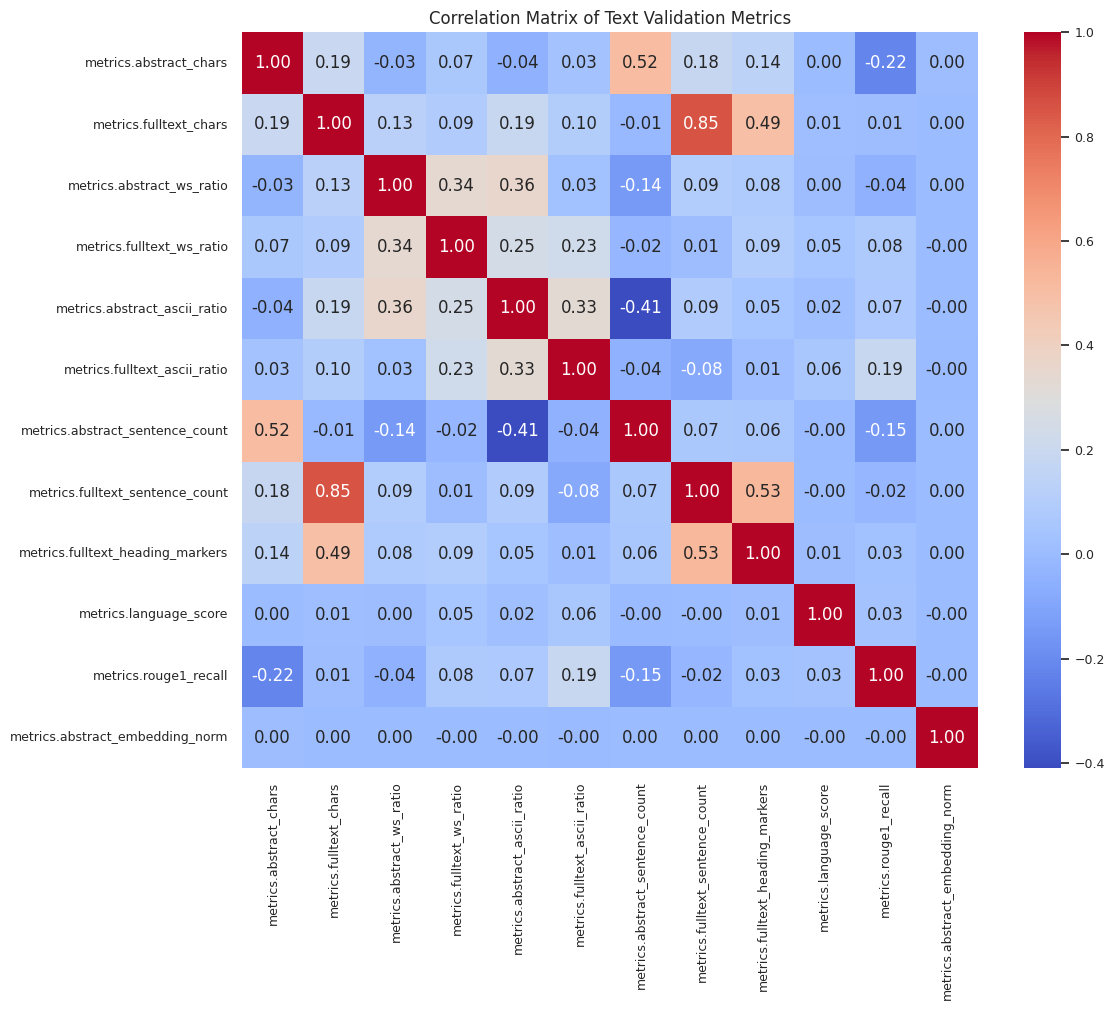

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns of interest
metric_cols = [
    "metrics.abstract_chars", "metrics.fulltext_chars",
    "metrics.abstract_ws_ratio", "metrics.fulltext_ws_ratio",
    "metrics.abstract_ascii_ratio", "metrics.fulltext_ascii_ratio",
    "metrics.abstract_sentence_count", "metrics.fulltext_sentence_count",
    "metrics.fulltext_heading_markers", "metrics.language_score",
    "metrics.rouge1_recall", 
    "metrics.abstract_embedding_norm"
]

# Clean data
numeric_df = df[metric_cols].dropna()

# Compute Pearson correlation
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Matrix of Text Validation Metrics")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "metric_correlation_heatmap.png"))
plt.show()


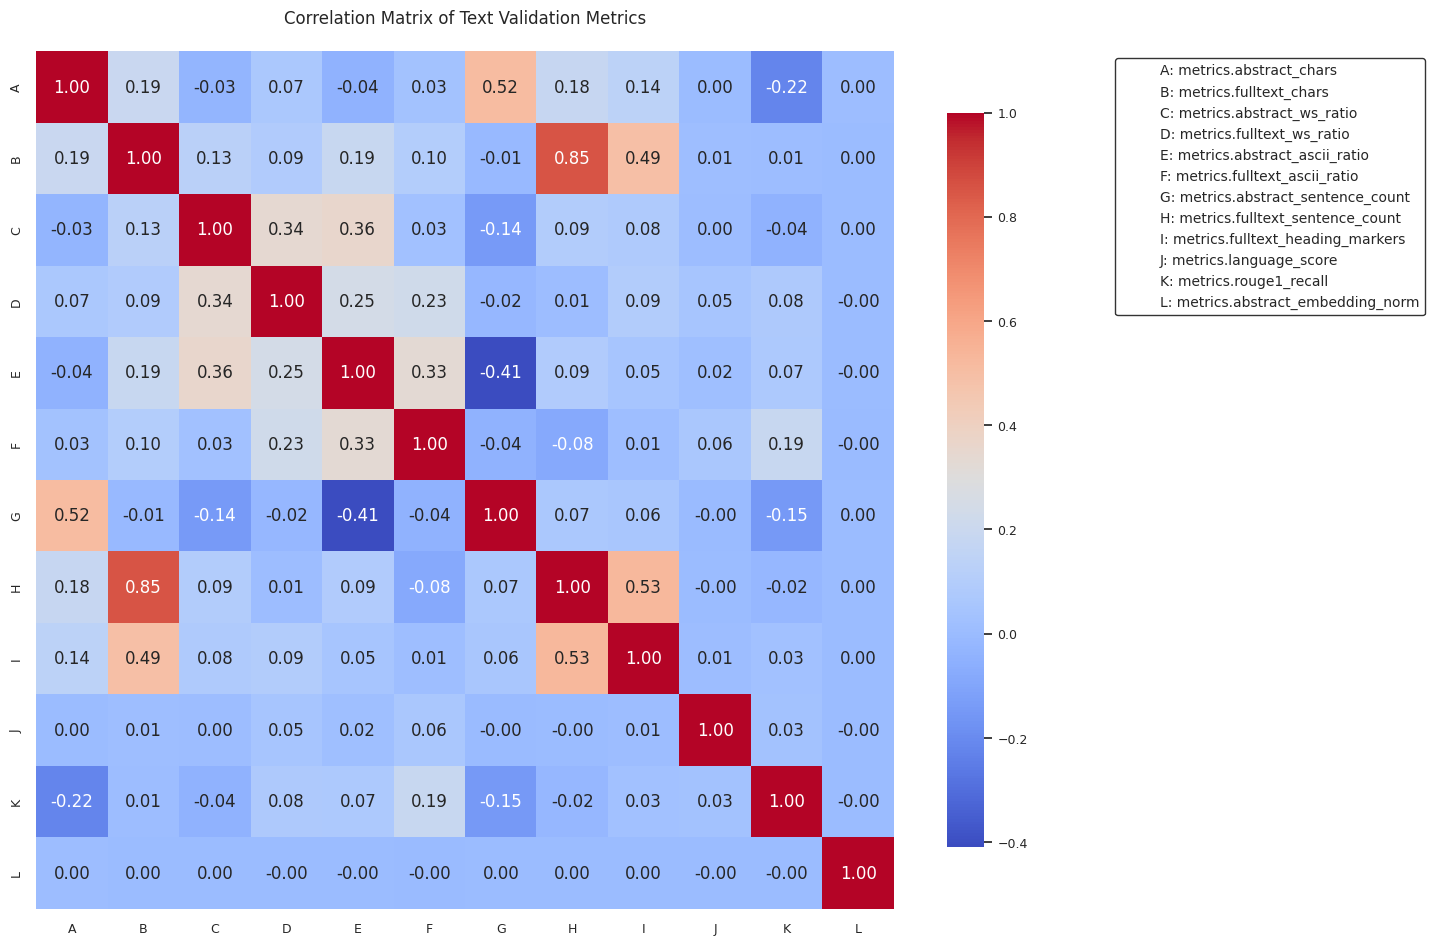

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
import string
import os

# Select numeric columns of interest
metric_cols = [
    "metrics.abstract_chars", "metrics.fulltext_chars",
    "metrics.abstract_ws_ratio", "metrics.fulltext_ws_ratio",
    "metrics.abstract_ascii_ratio", "metrics.fulltext_ascii_ratio",
    "metrics.abstract_sentence_count", "metrics.fulltext_sentence_count",
    "metrics.fulltext_heading_markers", "metrics.language_score",
    "metrics.rouge1_recall", 
    "metrics.abstract_embedding_norm"
]

# Generate codes A, B, C, ...
codes = list(string.ascii_uppercase[:len(metric_cols)])
code_mapping = dict(zip(metric_cols, codes))

# Clean data
numeric_df = df[metric_cols].dropna()

# Compute Pearson correlation
corr_matrix = numeric_df.corr()

# Rename for coded heatmap
corr_matrix_code = corr_matrix.rename(index=code_mapping, columns=code_mapping)

# Create figure with extra width for legend
fig, ax = plt.subplots(figsize=(14, 10))

# Plot heatmap with colorbar aligned to matrix size
sns.heatmap(
    corr_matrix_code,
    annot=True, fmt=".2f",
    cmap="coolwarm", square=True,
    cbar_kws={"shrink": 0.82},  # shrink colorbar to match heatmap height
    ax=ax
)

# Title
ax.set_title("Correlation Matrix of Text Validation Metrics", pad=20)

# Create legend mapping codes to metrics
legend_elements = [
    plt.Line2D([0], [0], color='white', label=f"{codes[i]}: {metric_cols[i]}")
    for i in range(len(metric_cols))
]

# Place legend far to the right with border
legend = ax.legend(
    handles=legend_elements,
    loc='upper left',
    bbox_to_anchor=(1.25, 1),  # move further away
    frameon=True,              # show border
    facecolor='white',
    edgecolor='black',
    fontsize=10
)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "metric_correlation_heatmap_with_codes_fixed.png"))
plt.show()



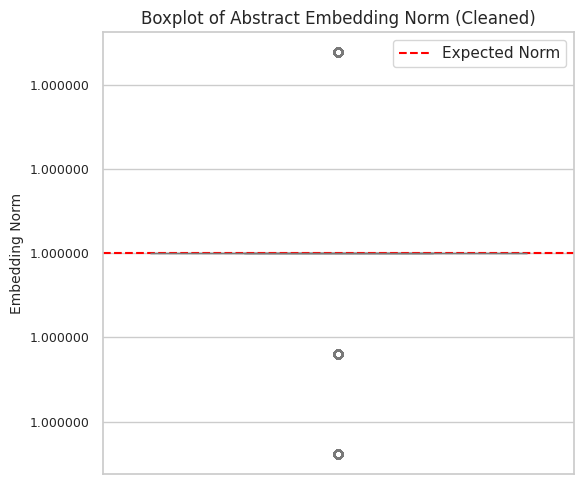

In [14]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os

# Cleaned embedding norm series
df_clean = df["metrics.abstract_embedding_norm"].dropna()
df_clean = df_clean[df_clean > 0]  # optional: filter out zeros

plt.figure(figsize=(6, 5))
sns.boxplot(y=df_clean, color="lightblue")
plt.title("Boxplot of Abstract Embedding Norm (Cleaned)")
plt.ylabel("Embedding Norm")

# Fix y-axis formatting to show raw values around 1.0
ax = plt.gca()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.6f}"))
ax.yaxis.offsetText.set_visible(False)  # Remove +1 offset

# Add expected norm reference line
plt.axhline(1.0, color="red", linestyle="--", label="Expected Norm")
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "embedding_norm_boxplot_fixed_final.png"))
plt.show()
plt.close()


/tmp/ipykernel_1957066/2247403512.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


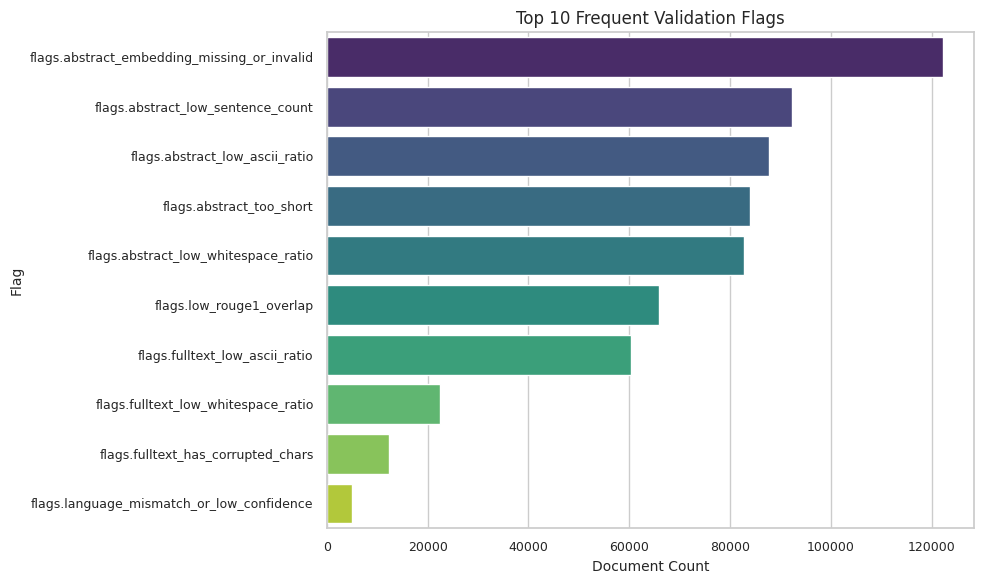

✅ All reports saved to: ./figures_tables/text_analysis_output


In [15]:
# --- Countplot: Top 10 Flags ---
plt.figure(figsize=(10, 6))
sns.barplot(
    y="flag", x="count",
    data=flag_summary.head(10),
    palette="viridis"
)
plt.title("Top 10 Frequent Validation Flags")
plt.xlabel("Document Count")
plt.ylabel("Flag")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "top_flags_barplot.png"))
plt.show()
plt.close()

print("✅ All reports saved to:", OUTPUT_DIR)
